In [1]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

FIG = Path("figs")
DATA = FIG / "data"
OUTPUT = FIG / "Fig3.pdf"

plt.rcParams.update({
    "font.family": "STIXGeneral",
    "mathtext.fontset": "stix",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.linewidth": 0.8,
    "savefig.dpi": 240,
})

In [2]:
with np.load(DATA / "fig3_c_VI_g10p300000_g20p800000_n400_T70p000_dt0p0600_eps0p300.npz") as raw:
    vi = {key: raw[key] for key in raw.files}
with np.load(DATA / "fig3_d_VII_g10p300000_g20p800000_n400_T70p000_dt0p0600_eps0p300.npz") as raw:
    vii = {key: raw[key] for key in raw.files}

grid_vi = vi["grid"].astype(int)
grid_vii = vii["grid"].astype(int)

phi1_vi = vi["phi1"].astype(float)
phi2_vi = vi["phi2"].astype(float)
phi1_vii = vii["phi1"].astype(float)
phi2_vii = vii["phi2"].astype(float)

extent_vi = tuple(vi["extent"].astype(float))
extent_vii = tuple(vii["extent"].astype(float))

gamma1 = float(vi["g1"])
gamma2 = float(vi["g2"])

gamma1_axis = np.linspace(0.0, 1.0, 400)

basin_colors = [str(x) for x in vi["cmap_hex"]]
basin_cmap = ListedColormap(basin_colors)

one_fixed_color = "#F8F8FC"
three_fixed_color = "#F1F1FF"
five_fixed_color = "#E2DEFF"
curve_vi = "#7C69C9"
curve_vii_2to1 = "#9875C8"
curve_vii_1to1 = "#B7A7E8"

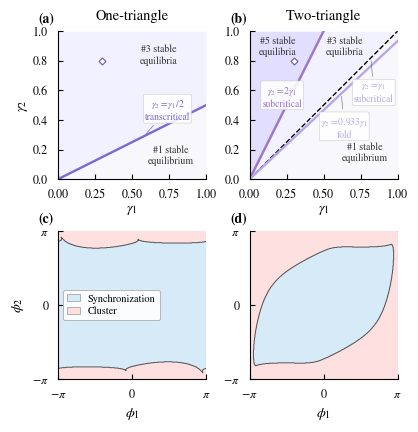

In [3]:
fig = plt.figure(figsize=(5.05, 4.18))
gs = fig.add_gridspec(
    2, 2,
    hspace=0.35,
    wspace=-0.25,
    left=0.105,
    right=0.990,
    top=0.930,
    bottom=0.098,
)

ax_a = fig.add_subplot(gs[0, 0])
ax_b = fig.add_subplot(gs[0, 1])
ax_c = fig.add_subplot(gs[1, 0])
ax_d = fig.add_subplot(gs[1, 1])

label_box = {
    "boxstyle": "round,pad=0.14",
    "fc": "white",
    "ec": "0.75",
    "lw": 0.35,
    "alpha": 0.88,
}
arrow_style = {
    "arrowstyle": "-",
    "color": "0.45",
    "lw": 0.45,
    "shrinkA": 2,
    "shrinkB": 2,
}

ax_a.fill_between(gamma1_axis, 0.0, gamma1_axis / 2.0, color=one_fixed_color, lw=0)
ax_a.fill_between(gamma1_axis, gamma1_axis / 2.0, 1.0, color=three_fixed_color, lw=0)
ax_a.plot(gamma1_axis, gamma1_axis / 2.0, color=curve_vi, lw=1.7)

ax_a.text(0.76, 0.16, "#1 stable\nequilibrium",
          color="#333333", fontsize=7.1, ha="center", va="center")
ax_a.text(0.68, 0.84, "#3 stable\nequilibria",
          color="#333333", fontsize=7.1, ha="center", va="center")

ax_a.annotate(
    r"$\gamma_{2}=\gamma_{1}/2$" + "\ntranscritical",
    xy=(0.58, 0.29),
    xytext=(0.74, 0.47),
    fontsize=6.9,
    color=curve_vi,
    ha="center",
    va="center",
    bbox=label_box,
    arrowprops=arrow_style,
)
ax_a.plot(gamma1, gamma2, marker="D", ms=3.5, linestyle="None",
          markerfacecolor="white", markeredgecolor="#6F5FA8",
          markeredgewidth=0.85)

ax_a.set_xlim(0.0, 1.0)
ax_a.set_ylim(0.0, 1.0)
ax_a.set_aspect("equal")
ax_a.set_xlabel(r"$\gamma_1$", fontsize=10.0, labelpad=2.2)
ax_a.set_ylabel(r"$\gamma_2$", fontsize=10.0, labelpad=2.2)
ax_a.set_title("One-triangle", fontsize=10.4, pad=8)
ax_a.tick_params(direction="in", pad=7.0, labelsize=8.6)
ax_a.text(-0.13, 1.04, "(a)", transform=ax_a.transAxes,
          fontsize=9.8, fontweight="bold", ha="left", va="bottom", clip_on=False)

ax_b.fill_between(gamma1_axis, 0.0, gamma1_axis, color=one_fixed_color, lw=0)
ax_b.fill_between(
    gamma1_axis,
    gamma1_axis,
    np.minimum(2.0 * gamma1_axis, 1.0),
    color=three_fixed_color,
    lw=0,
)
ax_b.fill_between(
    gamma1_axis,
    np.minimum(2.0 * gamma1_axis, 1.0),
    1.0,
    color=five_fixed_color,
    lw=0,
)
ax_b.plot(gamma1_axis, 2.0 * gamma1_axis, color=curve_vii_2to1, lw=1.7)
ax_b.plot(gamma1_axis, gamma1_axis, 'k--', lw=1)
ax_b.plot(gamma1_axis, 0.933 * gamma1_axis, color=curve_vii_1to1, lw=1.7)

ax_b.text(0.78, 0.18, "#1 stable\nequilibrium",
          color="#333333", fontsize=7.1, ha="center", va="center")
ax_b.text(0.64, 0.90, "#3 stable\nequilibria",
          color="#333333", fontsize=7.1, ha="center", va="center")
ax_b.text(0.19, 0.90, "#5 stable\nequilibria",
          color="#333333", fontsize=7.1, ha="center", va="center")

ax_b.annotate(
    r"$\gamma_{2}=2\gamma_{1}$" + "\nsubcritical",
    xy=(0.33, 0.66),
    xytext=(0.22, 0.56),
    fontsize=6.9,
    color=curve_vii_2to1,
    ha="center",
    va="center",
    bbox=label_box,
    arrowprops=arrow_style,
)
ax_b.annotate(
    r"$\gamma_{2}=\gamma_{1}$" + "\nsubcritical",
    xy=(0.82, 0.82),
    xytext=(0.84, 0.58),
    fontsize=6.9,
    color=curve_vii_1to1,
    ha="center",
    va="center",
    bbox=label_box,
    arrowprops=arrow_style,
)

ax_b.annotate(
    r"$\gamma_{2}=0.933 \gamma_{1}$" + "\nfold",
    xy=(0.62, 0.933*0.62),
    xytext=(0.64, 0.35),
    fontsize=6.9,
    color=curve_vii_1to1,
    ha="center",
    va="center",
    bbox=label_box,
    arrowprops=arrow_style,
)

ax_b.plot(gamma1, gamma2, marker="D", ms=3.5, linestyle="None",
          markerfacecolor="white", markeredgecolor="#6F5FA8",
          markeredgewidth=0.85)

ax_b.set_xlim(0.0, 1.0)
ax_b.set_ylim(0.0, 1.0)
ax_b.set_aspect("equal")
ax_b.set_xlabel(r"$\gamma_1$", fontsize=10.0, labelpad=2.2)
ax_b.set_title("Two-triangle", fontsize=10.4, pad=8)
ax_b.tick_params(direction="in", pad=7.0, labelsize=8.6)
ax_b.text(-0.13, 1.04, "(b)", transform=ax_b.transAxes,
          fontsize=9.8, fontweight="bold", ha="left", va="bottom", clip_on=False)

ax_c.imshow(
    grid_vi,
    origin="lower",
    extent=extent_vi,
    cmap=basin_cmap,
    vmin=0,
    vmax=2,
    aspect="equal",
    interpolation="nearest",
)

X_vi, Y_vi = np.meshgrid(phi1_vi, phi2_vi)
cluster_mask_vi = (grid_vi == 1).astype(float)
ax_c.contour(
    X_vi,
    Y_vi,
    cluster_mask_vi,
    levels=[0.5],
    colors="0.28",
    linewidths=0.7,
    alpha=0.92,
)

leg = ax_c.legend(
    handles=[
        Patch(facecolor=basin_colors[0], edgecolor="0.65",linewidth=0.6, label="Synchronization"),
        Patch(facecolor=basin_colors[1], edgecolor="0.65",linewidth=0.6, label="Cluster"),
    ],
    loc="center left",
    fontsize=7.4,
    frameon=True,
    facecolor="white",
    edgecolor="0.65",
    framealpha=0.9,
    borderpad=0.4,
    labelspacing=0.3,
    handlelength=1.2,
)
leg.get_frame().set_linewidth(0.6)

ax_c.set_xticks([-np.pi, 0.0, np.pi])
ax_c.set_xticklabels([r"$-\pi$", "0", r"$\pi$"])
ax_c.set_yticks([-np.pi, 0.0, np.pi])
ax_c.set_yticklabels([r"$-\pi$", "0", r"$\pi$"])
ax_c.set_xlabel(r"$\phi_1$", fontsize=10.2)
ax_c.set_ylabel(r"$\phi_2$", fontsize=10.2)
ax_c.tick_params(direction="in", pad=7.0, labelsize=8.7)
ax_c.text(-0.13, 1.04, "(c)", transform=ax_c.transAxes,
          fontsize=9.8, fontweight="bold", ha="left", va="bottom", clip_on=False)

ax_d.imshow(
    grid_vii,
    origin="lower",
    extent=extent_vii,
    cmap=basin_cmap,
    vmin=0,
    vmax=2,
    aspect="equal",
    interpolation="nearest",
)

X_vii, Y_vii = np.meshgrid(phi1_vii, phi2_vii)
cluster_mask_vii = (grid_vii == 1).astype(float)
ax_d.contour(
    X_vii,
    Y_vii,
    cluster_mask_vii,
    levels=[0.5],
    colors="0.28",
    linewidths=0.7,
    alpha=0.92,
)

ax_d.set_xticks([-np.pi, 0.0, np.pi])
ax_d.set_xticklabels([r"$-\pi$", "0", r"$\pi$"])
ax_d.set_yticks([-np.pi, 0.0, np.pi])
ax_d.set_yticklabels([r"$-\pi$", "0", r"$\pi$"])
ax_d.set_xlabel(r"$\phi_1$", fontsize=10.2)
ax_d.tick_params(direction="in", pad=7.0, labelsize=8.7)
ax_d.text(-0.13, 1.04, "(d)", transform=ax_d.transAxes,
          fontsize=9.8, fontweight="bold", ha="left", va="bottom", clip_on=False)

fig.savefig(OUTPUT, dpi=240, bbox_inches="tight", pad_inches=0)
plt.show()